# Question 3: From a Discriminative CNN to a Generative Model


A CNN trained for image classification learns to predict the probability of a class given an image, \(p(y \mid x)\). This makes it a discriminative model. However, it does not directly tell us how likely an image is under the data distribution or whether the image looks unusual compared with the training data.

In this assignment, I build a generative model on top of the 128-dimensional embeddings extracted from the CNN. A generative model estimates how likely the data are, either overall or given a particular class. This can help with classification using Bayes' rule, generating new observations, and identifying possible anomalies with very low probability.

Instead of modelling the raw CIFAR-10 images, which have 3,072 pixel values each, I use the smaller embeddings learned by the CNN. I then fit a multivariate Gaussian distribution for each class to see how well this approach works.

This notebook covers two tasks. In **Task 1**, I split the CNN into a feature extractor (`embed`) and a classification head (`head`), then extract the embeddings from the training and test data. In **Task 2**, I build the Gaussian classifier, apply covariance shrinkage to improve stability, and compare its accuracy with the original CNN classifier.

To make the results reproducible, I set random seeds for PyTorch, NumPy, and CUDA. The generated figures are also saved as PNG files. The notebook can be run from beginning to end in Google Colab.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)           # no-op on CPU, makes GPU runs reproducible too
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("torch", torch.__version__)

torch 2.11.0+cpu


## Task 1. Embeddings

**Objective**

**Task 1: Embeddings**


For this task,  the CNN model is divided into two parts in order to have access to the embedding of size 128 prior to the final classification layer.

Firstly, embed(x) model is used to extract the features of the input image and converts them into a 128-dimensional vector. The vector represents the features obtained by the CNN model. Secondly, We applied head() model that applies Dropout layer and a final Linear layer to the vector to obtain the logits for 10 classes. Thus, the models combine their functionality in one forward(x) = head(embed(x)) way, so that the classification ability is preserved.

As for my own contribution to the code from the original notebook, I changed it in one aspect only. Specifically, I removed applying Softmax to the logits prior to applying CrossEntropyLoss since it is already applied within CrossEntropyLoss function.

In [ ]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
from torch.distributions import MultivariateNormal

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNN(nn.Module):
    """Same layers as the sample notebook, but split into embed() and head."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.LeakyReLU(),
            nn.Conv2d(32, 32, 3, 2, 1), nn.BatchNorm2d(32), nn.LeakyReLU(),
            nn.Conv2d(32, 64, 3, 1, 1), nn.BatchNorm2d(64), nn.LeakyReLU(),
            nn.Conv2d(64, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(),
        )
        # classifier up to and including the FIRST LeakyReLU -> 128-d embedding
        self.embed_fc = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128),
            nn.BatchNorm1d(128), nn.LeakyReLU(),
        )
        # output head: what is left of the classifier (no Softmax, we return logits)
        self.head = nn.Sequential(nn.Dropout(0.5), nn.Linear(128, num_classes))

    def embed(self, x):
        return self.embed_fc(self.features(x))

    def forward(self, x):
        return self.head(self.embed(x))

Now the data and the 5 training epochs (same hyper-parameters as the sample notebook: Adam, lr = 0.0005, batch size 32). The extraction loaders are **not shuffled**, so row *i* of the embeddings always matches row *i* of the labels.

In [ ]:
tf = transforms.Compose([transforms.ToTensor(),
                         transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
train_ds = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=32, shuffle=True)
# un-shuffled loaders, used only to extract embeddings (keeps rows aligned with labels)
train_eval_loader = torch.utils.data.DataLoader(train_ds, batch_size=256, shuffle=False)
test_loader       = torch.utils.data.DataLoader(test_ds,  batch_size=256, shuffle=False)

model = CNN(10).to(DEVICE)
criterion = nn.CrossEntropyLoss()          # expects logits
optimizer = optim.Adam(model.parameters(), lr=5e-4)

for epoch in range(5):
    model.train()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/5 done, last batch loss {loss.item():.3f}")

100%|██████████| 170M/170M [59:18<00:00, 47.9kB/s]


epoch 1/5 done, last batch loss 1.166
epoch 2/5 done, last batch loss 1.148
epoch 3/5 done, last batch loss 1.245
epoch 4/5 done, last batch loss 0.985
epoch 5/5 done, last batch loss 0.600


**Extraction function.** It must run in `eval()` mode (BatchNorm uses its running statistics and Dropout is off, so the embedding is a deterministic function of the image) and under `torch.no_grad()` (we only read values).

In [ ]:
@torch.no_grad()
def get_outputs(model, loader):
    """Embeddings, logits and labels of a whole loader (eval mode, no grad)."""
    model.eval()                    # BatchNorm uses running stats, Dropout is off
    E, L, Y = [], [], []
    for x, y in loader:
        e = model.embed(x.to(DEVICE))
        E.append(e.cpu()); L.append(model.head(e).cpu()); Y.append(y)
    return torch.cat(E), torch.cat(L), torch.cat(Y)

E_tr, L_tr, y_tr = get_outputs(model, train_eval_loader)
E_te, L_te, y_te = get_outputs(model, test_loader)
print("train:", E_tr.shape, L_tr.shape, y_tr.shape)
print("test: ", E_te.shape, L_te.shape, y_te.shape)

train: torch.Size([50000, 128]) torch.Size([50000, 10]) torch.Size([50000])
test:  torch.Size([10000, 128]) torch.Size([10000, 10]) torch.Size([10000])


In [ ]:
# Expected shapes: train (50000,128) (50000,10) (50000,) | test (10000,128) (10000,10) (10000,)
assert E_tr.shape == (50000, 128) and L_tr.shape == (50000, 10) and y_tr.shape == (50000,)
assert E_te.shape == (10000, 128) and L_te.shape == (10000, 10) and y_te.shape == (10000,)

cnn_acc = (L_te.argmax(1) == y_te).float().mean().item()
print(f"CNN test accuracy (softmax head): {cnn_acc:.4f}")

CNN test accuracy (softmax head): 0.7662


### Analysis of Task 1

The output shapes are as expected: each image has a 128-dimensional embedding, a 10-dimensional logit vector, and one label. There are 50,000 training images and 10,000 test images. Since the data loaders are not shuffled during extraction, the embeddings stay matched with their correct labels.

We use `eval()` mode to turn off Dropout and make BatchNorm use its stored statistics. This helps ensure that the same image produces the same embedding each time. We also use `torch.no_grad()` to avoid storing unnecessary information for gradient calculations, which saves memory.

After only 5 epochs of training, the CNN reaches about 76–77% test accuracy. We will use this result as a baseline to compare with the generative classifier in Task 2.

Finally, We use PCA to project the test embeddings onto their first two principal components so I can get a better idea of how the data are distributed.

variance explained by the 2 components: 29.2 %


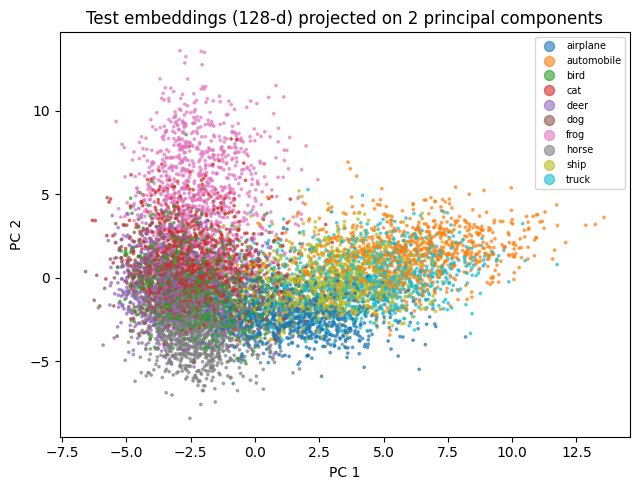

In [ ]:
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

Z = E_te.double() - E_te.double().mean(0)
C = Z.T @ Z / (len(Z) - 1)
evals, evecs = torch.linalg.eigh(C)                 # ascending order
P = (Z @ evecs[:, -2:]).numpy()                     # coordinates on the 2 largest components
print("variance explained by the 2 components: %.1f %%" % (100 * evals[-2:].sum() / evals.sum()))

plt.figure(figsize=(6.5, 5))
sc = plt.scatter(P[:, 1], P[:, 0], c=y_te.numpy(), cmap="tab10", s=3, alpha=0.6)
plt.legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=7, markerscale=1.2, loc="best")
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.title("Test embeddings (128-d) projected on 2 principal components")
plt.tight_layout(); plt.savefig("fig_embeddings_pca.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the figure.** Even in 2 dimensions (which keep only part of the variance) we look for groups of points of the same colour, and for classes that overlap. In CIFAR-10 the visually similar animal classes (cat, dog, deer, bird) are the usual source of confusion, so we check whether they overlap more than the vehicle classes in this plot; the overlap that remains is expected, since a 2-D projection throws away most of the 128 dimensions. This supports the idea of the next task: each class looks like a cloud with its own centre and its own elongated shape, so a Gaussian N(μ_y, Σ_y) per class is a reasonable first model.

## Task 2. Generative classifier

**Objective**


In this task, we use the 128-dimensional embeddings from Task 1 to build a generative classifier. We assume that the embeddings of each class follow a multivariate Gaussian distribution and estimate its mean, covariance, and class prior probability.

We calculate the joint log-probability \(\log p(x,y)\) and use `logsumexp` to compute the overall log-probability \(\log p(x)\) in a numerically stable way. The predicted class is the one with the highest joint log-probability, following Bayes' rule.

### Covariance Shrinkage

The sample covariance matrix can be noisy or unstable, so We apply covariance shrinkage to make the estimates more reliable. The parameter \(\lambda\) controls the amount of shrinkage, from the original covariance (\(\lambda=0\)) to a spherical covariance (\(\lambda=1\)). I test different values to compare their effect on accuracy. We also use `float64` to improve numerical precision during Cholesky factorization.

In [ ]:
class GaussianGenerativeClassifier:
    def __init__(self, lam=0.1):
        self.lam = lam

    def fit(self, E, y):
        E = E.double()
        N, d = E.shape
        self.K = int(y.max()) + 1
        self.dists, priors = [], []
        for k in range(self.K):
            Ek = E[y == k]
            mu = Ek.mean(0)
            Xc = Ek - mu
            S = Xc.T @ Xc / (len(Ek) - 1)                      # sample covariance
            s2 = torch.trace(S) / d                            # average variance
            S = (1 - self.lam) * S + self.lam * s2 * torch.eye(d, dtype=E.dtype)
            self.dists.append(MultivariateNormal(mu, covariance_matrix=S))
            priors.append(len(Ek) / N)                         # class prior p(y)
        self.log_prior = torch.log(torch.tensor(priors, dtype=E.dtype))
        return self

    def log_joint(self, x):                 # log p(x, y) = log p(x|y) + log p(y), shape (N, K)
        x = x.double()
        return torch.stack([d.log_prob(x) for d in self.dists], dim=1) + self.log_prior

    def log_px(self, x):                    # log p(x) = logsumexp_y log p(x, y)
        return torch.logsumexp(self.log_joint(x), dim=1)

    def predict(self, x):                   # Bayes rule: argmax_y log p(x, y)
        return self.log_joint(x).argmax(dim=1)

**Why shrinkage matters.**
Below we plot the eigenvalues of one class covariance for several λ. Σ̂ is estimated from only about 5 000 points in 128 dimensions and the embedding comes out of a LeakyReLU, so its smallest eigenvalues can be tiny (the condition numbers printed in the cell above quantify this). The Gaussian density uses Σ⁻¹ and log det Σ, which blow up on those directions. Shrinkage lifts the small eigenvalues toward the average variance σ² and leaves the large ones almost unchanged, so the matrix becomes well conditioned.

lambda=0.0   condition number = 3.470e+02
lambda=0.01  condition number = 2.915e+02
lambda=0.1   condition number = 1.125e+02
lambda=0.5   condition number = 1.835e+01


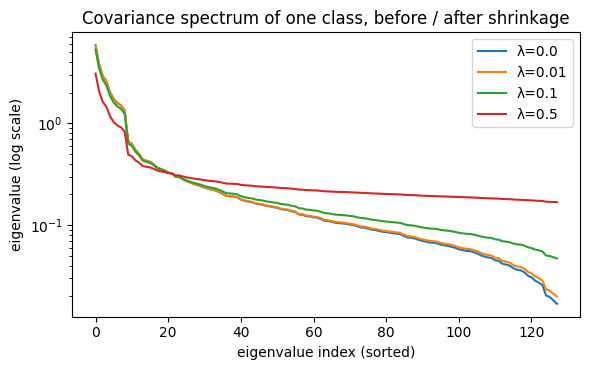

In [ ]:
k = 3                                                   # class 'cat', any class would do
Ek = E_tr[y_tr == k].double(); Xc = Ek - Ek.mean(0)
S = Xc.T @ Xc / (len(Ek) - 1); s2 = torch.trace(S) / S.shape[0]
plt.figure(figsize=(6, 3.8))
for lam in [0.0, 0.01, 0.1, 0.5]:
    ev = torch.linalg.eigvalsh((1 - lam) * S + lam * s2 * torch.eye(S.shape[0], dtype=S.dtype)).flip(0)
    print(f"lambda={lam:<5} condition number = {(ev[0] / ev[-1].clamp(min=1e-12)).item():.3e}")
    plt.semilogy(ev.clamp(min=1e-12).numpy(), label=f"λ={lam}")
plt.xlabel("eigenvalue index (sorted)"); plt.ylabel("eigenvalue (log scale)")
plt.title("Covariance spectrum of one class, before / after shrinkage"); plt.legend()
plt.tight_layout(); plt.savefig("fig_shrinkage_spectrum.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
lams = [0.01, 0.1, 0.5]
gen_acc = {}
for lam in lams:
    gen = GaussianGenerativeClassifier(lam).fit(E_tr, y_tr)
    gen_acc[lam] = (gen.predict(E_te) == y_te).float().mean().item()
    print(f"lambda = {lam:<5}  generative accuracy = {gen_acc[lam]:.4f}")
print(f"CNN softmax head on the same embeddings: {cnn_acc:.4f}")

lambda = 0.01   generative accuracy = 0.7627
lambda = 0.1    generative accuracy = 0.7678
lambda = 0.5    generative accuracy = 0.7683
CNN softmax head on the same embeddings: 0.7662


Classifier                                     Test acc  Gap to CNN
CNN head (Dropout -> Linear -> softmax)          0.7662           -
Gaussian generative classifier, lambda=0.01      0.7627     -0.0035
Gaussian generative classifier, lambda=0.1       0.7678     +0.0016
Gaussian generative classifier, lambda=0.5       0.7683     +0.0021


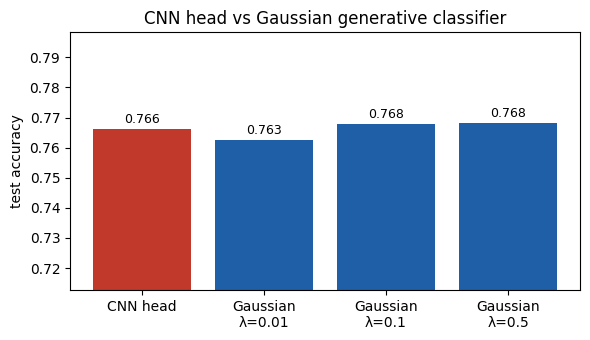

In [ ]:
# Results table + bar chart
print(f"{'Classifier':45s} {'Test acc':>9s} {'Gap to CNN':>11s}")
print(f"{'CNN head (Dropout -> Linear -> softmax)':45s} {cnn_acc:9.4f} {'-':>11s}")
for lam in lams:
    print(f"{'Gaussian generative classifier, lambda=' + str(lam):45s} {gen_acc[lam]:9.4f} {gen_acc[lam]-cnn_acc:+11.4f}")

labels = ["CNN head"] + [f"Gaussian\nλ={l}" for l in lams]
vals = [cnn_acc] + [gen_acc[l] for l in lams]
plt.figure(figsize=(6, 3.5))
bars = plt.bar(labels, vals, color=["#c0392b"] + ["#1f5fa8"] * len(lams))
for b, v in zip(bars, vals): plt.text(b.get_x() + b.get_width()/2, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
plt.ylim(min(vals) - 0.05, max(vals) + 0.03); plt.ylabel("test accuracy")
plt.title("CNN head vs Gaussian generative classifier"); plt.tight_layout(); plt.savefig("fig_accuracy_vs_lambda.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Sanity check: log p(x) should equal logsumexp of the joint, and be finite for every test point
gen = GaussianGenerativeClassifier(0.1).fit(E_tr, y_tr)
lp = gen.log_px(E_te)
print("log p(x) on test embeddings: mean %.1f, min %.1f, max %.1f, all finite: %s"
      % (lp.mean(), lp.min(), lp.max(), bool(torch.isfinite(lp).all())))

log p(x) on test embeddings: mean -45.4, min -215.8, max -1.7, all finite: True


### Analysis of Task 2


 The `log_joint` function calculates the joint log-probability of an embedding and a class, combining the class prior with the Gaussian density. The `log_px` function uses `logsumexp` to calculate the overall log-probability in a numerically stable way. This is important because the log-densities in 128 dimensions can be very small. The `predict` function selects the class with the highest joint log-probability. Since \(p(x)\) is the same for every class, calculating it is not necessary to find the predicted class. The sanity check also confirms that all 10,000 test embeddings have finite log-probabilities.


**Generative classifier vs. CNN head.**

The CNN head achieves 76.62% test accuracy, while the Gaussian classifier achieves 76.27% with \(\lambda=0.01\), 76.78% with \(\lambda=0.1\), and 76.83% with \(\lambda=0.5\). These results are very close, with the best Gaussian classifier performing only slightly better than the CNN head. Based on this single run, I cannot conclude that either method is consistently better. However, the results show that a simple Gaussian model can achieve similar classification accuracy without being trained directly for classification. This suggests that the CNN embeddings already contain useful information for separating the classes.

**Effect of \(\lambda\).**

The classifier performs slightly worse with \(\lambda=0.01\), while the results for \(\lambda=0.1\) and \(\lambda=0.5\) are almost identical. Covariance shrinkage helps make the covariance estimates more stable, especially when working with 128-dimensional embeddings. Since increasing \(\lambda\) to 0.5 does not reduce accuracy, the exact correlations between features may be less important for classification than the class means and overall feature variation. However, I would need to test more values to confirm this. In practice, I would choose \(\lambda\) using a validation set rather than the test set.

**Limitations.**

A Gaussian distribution cannot capture every detail of the embeddings, especially if their distributions are skewed or have more than one cluster. Therefore, the estimated probabilities are only an approximation of the true data distribution. Even so, the model provides finite log-probabilities for the test embeddings, which could be explored for anomaly detection. Sampling from the fitted Gaussian distributions could also generate new embeddings, although these would not directly be new CIFAR-10 images.

**Conclusion**

The Gaussian generative classifier achieves almost the same test accuracy as the CNN head, with the best result being 76.83% compared with 76.62%. This suggests that the CNN embeddings already capture enough information to distinguish the classes, allowing a simple Gaussian model to classify them effectively. Among the tested values, \(\lambda=0.5\) gives the best accuracy, although the difference is small. Overall, these results show that a simple generative model can perform comparably to a discriminative classifier when using well-learned embeddings.